# Figure S8 — what TI and TD units do in the multitask RNN

One of two Extended Data figures on the multitask RNN (183 mm wide). Heavy computation lives in `src/mtrnn/panels/` and is
cached in `results/panels/<name>.pkl`; every plotting cell only reads the cache. The trained networks of the main
RNN figure (Figure 5) are reused; nothing is retrained. The ReLU networks are the 10 of `figure_5.ipynb`, and the
Softplus networks are trained the same way.

| panel | content |
|---|---|
| a | silencing TI, TD, Int or random choice units (matched n): each task of the pair, and the other 25 tasks |
| b | removal of TI, TD or random units from the decoder, by category: within, across, XOR |
| c | task-identity decoding over time from 5-unit TI or TD subsets |
| d | stimulus-side vs response-side selectivity in the reversed-mapping pairs |
| e | difference between the two tasks' rule-input weights |
| f | recurrent weights onto TI and TD units from the five source sets, with a label-permutation null |

**Exclusion:** a network is left out of every pair containing a task it performs below 0.90. This is Yang et al. 2019's criterion,
applied per network-task combination; applied per network it would remove 9 of the 10 ReLU networks, all for DNMS. The main figure
(`figure_5.ipynb`) uses the same rule. Panel a and the stats file list what was dropped.

**Statistics:** the unit of analysis is the network (n = 10). Values are averaged over the pairs of a category within each
network, then compared with paired two-sided Wilcoxon signed-rank tests (exact p; with n = 10 the smallest possible p is
0.002). Slopes are fitted inside each network and the 10 slopes are tested against zero.

**Outputs** (in `analysis/figures/figure_s8/`):
- `figs8.{pdf,svg,png}`
- `panels/<letter>.pdf`
- `figs8_stats.md`

Supplement to the multitask-RNN main figure, Figure 5 (`figure_5.ipynb`); the robustness checks are Figure S7 (`figure_s7.ipynb`, same cache and setup).

In [1]:
# ── setup: style, colours, layout helpers, cache ──
import os, sys, pickle, warnings
sys.path.insert(0, os.getcwd())                 # run from analysis/: paper_style.py, paper_stats.py, figure_layout.py
from paper_style import *                       # TI / TD / Int / random colours, coupling colours, puts ROOT on sys.path
from paper_stats import StatsTable
ST = StatsTable('figure_s8')          # Supplementary Table 1 rows (ED Fig. 8)
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy.stats import wilcoxon, spearmanr
from mtrnn import panels as EC, readout as Q
warnings.filterwarnings('ignore', category=RuntimeWarning)

OUT = figure_dir('figure_s8'); PANEL_DIR = OUT + 'panels/'; os.makedirs(PANEL_DIR, exist_ok=True); NAME = 'figs8'
# text sizes: the paper type scale (paper_style: axis labels 6 pt, ticks, legends and annotations 5 pt); 8-pt bold panel letters
apply_style()                                   # the shared type scale (paper_style); this figure also keeps 1-pt data lines
mpl.rcParams.update({'lines.linewidth': 1, 'pdf.fonttype': 42, 'ps.fonttype': 42})
LBL, TCK, LEG = FS_LABEL, FS_TICK, FS_LEGEND

TYPES = EC.TYPES
TYPE_C = {'same operation': '#2F6DB5', 'different operation': '#8DB8E8', 'spatial vs abstract': '#9C6ADE', 'reversed mapping': '#E8412C'}
TYPE_TICK = {'same operation': 'Same\nfam.', 'different operation': 'Diff.\nfam.', 'spatial vs abstract': 'Spat. vs\nabstr.', 'reversed mapping': 'Rev.\nmap.'}
TYPE_FULL = {'same operation': 'Same task family', 'different operation': 'Different task family', 'spatial vs abstract': 'Spatial vs abstract response',
             'reversed mapping': 'Reversed mapping'}   # Supplementary Table 1 dataset names
TYPE_LAB = {'same operation': 'Same fam.', 'different operation': 'Diff. fam.', 'spatial vs abstract': 'Spat. vs abstr.', 'reversed mapping': 'Rev. map.'}
ACT_C = {'ReLU': '#E8412C', 'Softplus': '#1E86B5'}
FAM_ORDER = [('Go', ['Go', 'RT Go', 'Dly Go', 'Go Mod1', 'Go Mod2', 'Sac']), ('Anti', ['Anti', 'RT Anti', 'Dly Anti']),
             ('Decision', ['DM 1', 'DM 2', 'Ctx DM 1', 'Ctx DM 2', 'MultSen DM']),
             ('Delayed decision', ['Dly DM 1', 'Dly DM 2', 'Ctx Dly DM 1', 'Ctx Dly DM 2', 'MultSen Dly DM']),
             ('Matching', ['DMS', 'DNMS', 'DMC', 'DNMC']), ('Pursuit', ['Pursuit']), ('Yes / no', ['Cat', 'Cat-B', 'Match'])]
TASK_ORDER = [t for _, ts in FAM_ORDER for t in ts]
FIVE, FIVE_TICKS = EC.FIVE, ['TI\nsame', 'TI\nopp.', 'TD\nsame', 'TD\nopp.', 'ctrl']
FIVE_STYLE = [(COUP_DARK, .9), (COUP_DARK, .4), (COUP_LIGHT, .9), (COUP_LIGHT, .4), (COUP_CTL, .9)]   # the noise-correlation bar colours (extra_noise_correlations)

C = lambda name: EC.load(name)
STATS = {}                                       # panel -> list of lines for the stats file
def stat(panel, line):
    STATS.setdefault(panel, []).append(line); print(f'  [{panel}] {line}')
pfmt = lambda p: f'{p:.2g}' if p >= 1e-3 else f'{p:.1e}'
def wsr(x, y=None):
    # paired two-sided Wilcoxon signed-rank, exact for n <= 25
    r = wilcoxon(x, y, alternative='two-sided', method='exact') if y is not None else wilcoxon(x, alternative='two-sided', method='exact')
    return float(r.pvalue)

def net_dots(ax, x, v, c, rng, width=.09, ms=3, open_=True):
    # open circles = networks, filled = mean ± s.e.m.
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    if not len(v): return
    ax.scatter(x + rng.uniform(-width, width, len(v)), v, s=ms, facecolor='white' if open_ else c, edgecolor=c, lw=.5, alpha=.9, zorder=2, clip_on=False)
    ax.errorbar(x, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt='o', ms=3, color=c, capsize=0, elinewidth=.8, zorder=3)
def mean_sem(ax, x, v, c, ms=3):
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    ax.errorbar(x, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt='o', ms=ms, color=c, capsize=0, elinewidth=.8, zorder=4)
def type_axis(ax):
    ax.set_xticks(range(len(TYPES))); ax.set_xticklabels([TYPE_TICK[t] for t in TYPES], fontsize=FS_TICK)
    for lab, t in zip(ax.get_xticklabels(), TYPES): lab.set_color(TYPE_C[t])
    ax.set_xlim(-.6, len(TYPES) - .4); ax.tick_params(axis='x', length=0, pad=2)
def top_legend(ax, handles, labels, ncol=None, y=1.0):
    ax.legend(handles, labels, fontsize=LEG, loc='lower left', bbox_to_anchor=(0, y), handletextpad=.1, borderaxespad=0,
              ncol=ncol or len(labels), columnspacing=.6, handlelength=1.0)
dot = lambda c, mfc=None: Line2D([], [], marker='o', ls='', color=c, mfc=mfc or c, ms=3)

# ── layout in millimetres: 183 mm wide, 6-mm outer margins, axes placed by absolute position (left, top, width, height) ──
MM = 1 / 25.4
FIG_W, FIG_H = 183, 92
COL = {1: 14, 2: 56, 3: 100, 4: 145}             # left edges of the four columns
ROW = {1: 13, 2: 55}                              # top edges of the two rows (rows 4-5 of the old single-page figure)
RH = 25                                           # axes height of a row
LAYOUT = {
    'a': [(COL[1], ROW[1], 54, RH), (COL[1] + 58, ROW[1], 14, RH)],
    'b': [(COL[3] + i * 27, ROW[1], 20, RH) for i in range(3)],
    'c': [(COL[1], ROW[2], 30, RH)],
    'd': [(COL[2], ROW[2], 30, RH)],
    'e': [(COL[3], ROW[2], 20, RH)],
    'f': [(COL[4], ROW[2], 14.5, RH), (COL[4] + 17.5, ROW[2], 14.5, RH)],
}
def add_axes_mm(fig, left, top, width, height, fw, fh):
    return fig.add_axes([left / fw, 1 - (top + height) / fh, width / fw, height / fh])
print({k: len(v) for k, v in LAYOUT.items()})

{'a': 2, 'b': 3, 'c': 1, 'd': 1, 'e': 1, 'f': 2}


In [2]:
# ── compute anything that is not cached yet (python -m mtrnn.panels: CPU panels ~20 min, GPU simulations ~3 min, silencing ~40 min on the GPU) ──
need = [p for p in ['performance', 'index_reliability', 'tail_size', 'softplus', 'pct_ti_within_type', 'noise_sweep', 'unit_removal', 'stim_vs_response', 'rule_weights', 'recurrent_weights', 'task_decoding_epochs', 'task_decoding', 'training_trajectory', 'silencing'] if not os.path.exists(f'{EC.CACHE}/{p}.pkl')]
run = {'task_decoding_epochs': EC.simulate_task_decoding, 'training_trajectory': lambda: (EC.simulate_training_trajectory(), EC.panel_training_trajectory())}
for p in need:
    print('computing', p); (run.get(p) or EC.PANELS[p])()
print('cache complete' if not need else f'computed {need}')
# panel g is calibrated against the data three-point of the paper's mouse window: same network sweep, new data values (no network is run)
PAPER_WINDOW = EC.PAPER_WINDOW
G_CACHE = f'noise_sweep_{PAPER_WINDOW}'
if not os.path.exists(f'{EC.CACHE}/{G_CACHE}.pkl'): EC.panel_noise_sweep_retarget(PAPER_WINDOW)

cache complete


## a · silencing and task performance

For every pair and network, the post-nonlinearity activity of n = min(n_TI, n_TD) ≥ 6 units is clamped to 0 at every time step. The
units are the pair's TI units, its TD units, its Int units (4 draws) or random choice units (4 draws; these include TI and TD units).
Performance on 200 trials of each task is compared with the intact network. Open circles = networks; filled = mean ± s.e.m.

**Left:** each task of the pair. Same- and different-family pairs average their two tasks. Spatial vs abstract pairs are split
into the spatial and the yes / no task; reversed-mapping pairs into the pro and the anti task.

**Right:** for 40 pairs (10 per category, the pairs of panel c), the same silencing measured on the other 25 tasks (as Yang et
al. 2019, Fig. 2e).

In [3]:
I_COND = [('random_n', '−random', C_RANDOM), ('Int_n', '−Int', '#8C8C8C'), ('TI_n', '−TI', C_TI), ('TD_n', '−TD', C_TD)]
I_GROUPS = [('same operation', None, 'Same\nfam.'), ('different operation', None, 'Diff.\nfam.'), ('spatial vs abstract', 'spatial', 'Spat.:\nspatial'),
            ('spatial vs abstract', 'abstract', 'Spat.:\nyes/no'), ('reversed mapping', 'pro', 'Rev.:\npro'), ('reversed mapping', 'anti', 'Rev.:\nanti')]

def silence_net(T, typ, rl):
    g = T[T.own & (T.type == typ)] if rl is None else T[T.own & (T.type == typ) & (T.role == rl)]
    return g.groupby(['seed', 'cond']).d_perf.mean().unstack()

def draw_a(axs):
    T = C('silencing')['table']; rng = np.random.default_rng(3); ax = axs[0]
    for gi, (typ, rl, lab) in enumerate(I_GROUPS):
        W = silence_net(T, typ, rl)
        for j, (c, _, col) in enumerate(I_COND): net_dots(ax, gi + (j - 1.5) * .2, W[c], col, rng, width=.04, ms=2)
    ax.axhline(0, color='k', ls='--', lw=.6); ax.set_xticks(range(len(I_GROUPS))); ax.set_xticklabels([g[2] for g in I_GROUPS], fontsize=FS_TICK)
    for t, (typ, _, _) in zip(ax.get_xticklabels(), I_GROUPS): t.set_color(TYPE_C[typ])
    ax.set_xlim(-.6, len(I_GROUPS) - .4); ax.tick_params(axis='x', length=0, pad=2); ax.set_ylabel('Δ performance\n(silenced − intact)', fontsize=LBL)
    top_legend(ax, [dot(c) for _, _, c in I_COND], [l for _, l, _ in I_COND])
    O = T[~T.own].groupby(['seed', 'cond']).d_perf.mean().unstack(); ax2 = axs[1]
    for j, (c, _, col) in enumerate(I_COND): net_dots(ax2, j, O[c], col, rng, width=.1, ms=2)
    ax2.axhline(0, color='k', ls='--', lw=.6); ax2.set_xticks(range(4)); ax2.set_xticklabels([l for _, l, _ in I_COND], fontsize=FS_TICK, rotation=90)
    ax2.set_xlim(-.6, 3.6); ax2.tick_params(axis='x', length=0, pad=1.5); ax2.set_title('other\n25 tasks', fontsize=FS_ANNOT, pad=2)
    lo = min(ax.get_ylim()[0], ax2.get_ylim()[0]); hi = max(ax.get_ylim()[1], ax2.get_ylim()[1], .02)
    for a_ in (ax, ax2): a_.set_ylim(lo, hi)
    ax2.set_yticklabels([])

d = C('silencing'); T = d['table']
stat('a', f'n = {T.seed.nunique()} networks, {T.groupby(["task_a", "task_b"]).ngroups} pairs (networks with n_TI, n_TD ≥ 6 that perform both tasks ≥ 0.90); 200 trials per task; '
          f'Int and random: {d["n_rand"]} draws; mean n silenced {T[T.own].n_removed.mean():.1f}')
for typ, rl, lab in I_GROUPS:
    W = silence_net(T, typ, rl); lab = lab.replace(chr(10), ' ')
    stat('a', f'{lab}: ' + ', '.join(f'{l} {W[c].mean():+.3f} ± {W[c].sem():.3f}' for c, l, _ in I_COND)
              + f'; −TD vs −Int p = {pfmt(wsr(W.TD_n, W.Int_n))}, −TD vs −random p = {pfmt(wsr(W.TD_n, W.random_n))}, −TI vs −Int p = {pfmt(wsr(W.TI_n, W.Int_n))}, −TI vs −TD p = {pfmt(wsr(W.TI_n, W.TD_n))}')
O = T[~T.own].groupby(['seed', 'cond']).d_perf.mean().unstack()
stat('a', f'other 25 tasks ({len(d["all27_pairs"])} pairs): ' + ', '.join(f'{l} {O[c].mean():+.4f} ± {O[c].sem():.4f}' for c, l, _ in I_COND)
          + f'; −TD vs −Int p = {pfmt(wsr(O.TD_n, O.Int_n))}, −TI vs −Int p = {pfmt(wsr(O.TI_n, O.Int_n))}, −TD vs −TI p = {pfmt(wsr(O.TD_n, O.TI_n))}')
for t in TYPES:
    Ot = T[(~T.own) & (T.type == t)].groupby(['seed', 'cond']).d_perf.mean().unstack()
    stat('a', f'   other tasks, {TYPE_LAB[t]} pairs: ' + ', '.join(f'{l} {Ot[c].mean():+.4f}' for c, l, _ in I_COND))

# Supplementary Table 1: one row per plotted condition (networks)
I_ROLE = {'spatial': 'spatial task', 'abstract': 'yes / no task', 'pro': 'pro task', 'anti': 'anti task'}
for typ, rl, lab in I_GROUPS:
    W = silence_net(T, typ, rl); ds = TYPE_FULL[typ] + ('' if rl is None else f': {I_ROLE[rl]}')
    for c, l, _ in I_COND:
        ST.group('a', W[c], dataset=ds, measure='Δ performance (silenced − intact)', group=l, unit='networks')
for c, l, _ in I_COND:
    ST.group('a', O[c], dataset=f'Other 25 tasks ({len(d["all27_pairs"])} pairs)', measure='Δ performance (silenced − intact)', group=l, unit='networks')

  [a] n = 10 networks, 350 pairs (networks with n_TI, n_TD ≥ 6 that perform both tasks ≥ 0.90); 200 trials per task; Int and random: 4 draws; mean n silenced 23.2
  [a] Same fam.: −random -0.063 ± 0.004, −Int -0.049 ± 0.005, −TI -0.143 ± 0.008, −TD -0.046 ± 0.010; −TD vs −Int p = 0.43, −TD vs −random p = 0.084, −TI vs −Int p = 0.002, −TI vs −TD p = 0.002
  [a] Diff. fam.: −random -0.069 ± 0.002, −Int -0.052 ± 0.003, −TI -0.166 ± 0.008, −TD -0.064 ± 0.010; −TD vs −Int p = 0.43, −TD vs −random p = 0.62, −TI vs −Int p = 0.002, −TI vs −TD p = 0.002
  [a] Spat.: spatial: −random -0.103 ± 0.007, −Int -0.104 ± 0.006, −TI -0.137 ± 0.015, −TD -0.078 ± 0.007; −TD vs −Int p = 0.02, −TD vs −random p = 0.0098, −TI vs −Int p = 0.049, −TI vs −TD p = 0.014
  [a] Spat.: yes/no: −random -0.153 ± 0.013, −Int -0.188 ± 0.016, −TI -0.298 ± 0.032, −TD -0.071 ± 0.015; −TD vs −Int p = 0.0039, −TD vs −random p = 0.002, −TI vs −Int p = 0.0098, −TI vs −TD p = 0.002
  [a] Rev.: pro: −random -0.060 ± 0.007, −Int -0

## b · removal and decoding, by category: within, across and XOR

On the decode half of each pair (labels from the other half), n = min(n_TI, n_TD) TI, TD or random choice units are removed and the
decoders are retrained. Within- and across-task choice use the paper's coding-direction decoder. XOR (choice XOR task identity) uses
the balanced four-condition decoder on trials of both tasks. Values are Δ accuracy relative to the full population; one point per
network (mean over the category's pairs), mean ± s.e.m.

In reversed-mapping pairs the stimulus side equals choice XOR task, so a unit that codes the stimulus decodes XOR linearly. The XOR
claim therefore rests on the same- and different-family pairs, where XOR is not a stimulus variable.

In [4]:
TYPE_SHORT = {'same operation': 'Same', 'different operation': 'Diff.', 'spatial vs abstract': 'Spat.', 'reversed mapping': 'Rev.'}
J_ORDER = [('-random', 'random', C_RANDOM), ('-TI', '−TI', LES_C['TI']), ('-TD', '−TD', LES_C['TD'])]
def draw_b(axs):
    T = C('unit_removal')['table']; rng = np.random.default_rng(4)
    for ax, (m, lab) in zip(axs, (('within', 'within'), ('across', 'across'), ('xor', 'XOR'))):
        for gi, t in enumerate(TYPES):
            W = T[T.type == t].groupby('seed').mean(numeric_only=True)
            for k, (name, _, c) in enumerate(J_ORDER): net_dots(ax, gi + (k - 1) * .26, W[f'{name}_{m}'], c, rng, width=.04, ms=1.6, open_=False)
        ax.axhline(0, color='k', ls='--', lw=.6); type_axis(ax); ax.set_title(lab, fontsize=LEG, pad=2)
        ax.set_xticklabels([TYPE_SHORT[t] for t in TYPES], fontsize=FS_TICK);   # one-word labels: the two-line ones overlap at 5 pt on these narrow axes ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
        for tl, t in zip(ax.get_xticklabels(), TYPES): tl.set_color(TYPE_C[t])
    axs[0].set_ylabel('Δ decoding acc.\n(vs full population)', fontsize=LBL)
    top_legend(axs[0], [dot(c) for _, _, c in J_ORDER], [l for _, l, _ in J_ORDER], y=1.12)

T = C('unit_removal')['table']
stat('b', f'n = {T.seed.nunique()} networks, {T.groupby(["task_a", "task_b"]).ngroups} pairs (n_TI, n_TD ≥ 6; ≥ 10 trials per task x choice condition); mean n removed {T.n_removed.mean():.1f}')
for t in TYPES:
    W = T[T.type == t].groupby('seed').mean(numeric_only=True)
    for m in ('within', 'across', 'xor'):
        stat('b', f'{TYPE_LAB[t]}, {m}: ' + ', '.join(f'{l} {W[f"{n}_{m}"].mean():+.4f} ± {W[f"{n}_{m}"].sem():.4f}' for n, l, _ in J_ORDER)
                  + f'; −TI vs random p = {pfmt(wsr(W[f"-TI_{m}"], W[f"-random_{m}"]))}, −TD vs random p = {pfmt(wsr(W[f"-TD_{m}"], W[f"-random_{m}"]))}')
W = T[T.type.isin(['same operation', 'different operation'])].groupby('seed').mean(numeric_only=True)
stat('b', f'XOR in same- and different-family pairs only (not a stimulus variable): −TD {W["-TD_xor"].mean():+.4f} ± {W["-TD_xor"].sem():.4f} vs random {W["-random_xor"].mean():+.4f}, p = {pfmt(wsr(W["-TD_xor"], W["-random_xor"]))}; '
          f'−TI {W["-TI_xor"].mean():+.4f}, p = {pfmt(wsr(W["-TI_xor"], W["-random_xor"]))}')

# Supplementary Table 1: one row per plotted condition (networks)
for t in TYPES:
    W = T[T.type == t].groupby('seed').mean(numeric_only=True)
    for m, mlab in (('within', 'choice within task'), ('across', 'choice across tasks'), ('xor', 'choice × task (XOR)')):
        for n_, l, _ in J_ORDER:
            ST.group('b', W[f'{n_}_{m}'], dataset=TYPE_FULL[t], measure=f'Δ accuracy, {mlab}', group={'-random': '− random', '-TI': '− TI', '-TD': '− TD'}[n_], unit='networks')

  [b] n = 10 networks, 350 pairs (n_TI, n_TD ≥ 6; ≥ 10 trials per task x choice condition); mean n removed 23.4
  [b] Same fam., within: random -0.0005 ± 0.0001, −TI -0.0030 ± 0.0004, −TD +0.0004 ± 0.0002; −TI vs random p = 0.002, −TD vs random p = 0.002
  [b] Same fam., across: random -0.0016 ± 0.0002, −TI -0.0170 ± 0.0031, −TD +0.0032 ± 0.0007; −TI vs random p = 0.002, −TD vs random p = 0.002
  [b] Same fam., xor: random -0.0049 ± 0.0002, −TI +0.0011 ± 0.0008, −TD -0.0149 ± 0.0009; −TI vs random p = 0.002, −TD vs random p = 0.002
  [b] Diff. fam., within: random -0.0005 ± 0.0001, −TI -0.0033 ± 0.0004, −TD +0.0003 ± 0.0002; −TI vs random p = 0.002, −TD vs random p = 0.002
  [b] Diff. fam., across: random -0.0024 ± 0.0002, −TI -0.0307 ± 0.0035, −TD +0.0041 ± 0.0010; −TI vs random p = 0.002, −TD vs random p = 0.002
  [b] Diff. fam., xor: random -0.0068 ± 0.0001, −TI +0.0010 ± 0.0008, −TD -0.0184 ± 0.0012; −TI vs random p = 0.002, −TD vs random p = 0.002
  [b] Spat. vs abstr., within: ra

## c · task identity over time

Task 1 vs task 2 is decoded in every 100-ms bin, aligned to the go cue, from 5-unit subsets of a pair's TI or TD units. A
mean-difference decoder is used, 5-fold cross-validated, with 100 subsets per class. To keep accuracy off ceiling, noise is added
at the σ that best matched the monkey data in g (the rule input is on throughout the trial). Ten random pairs per category are
used, with every network that performs both tasks.

Lines = mean ± s.e.m. over networks (network mean over pairs). Shading = median epoch boundaries of the tasks in these pairs:
fixation, stimulus, delay, response.

In [5]:
def draw_c(axs):
    ax = axs[0]; d = C('task_decoding'); T = d['table']; ep = d['epochs']; bms = ep['bin_ms']; pre = ep['pre_steps']
    tks = sorted(set(t for p in d['pairs'] for t in p)); E = ep['epochs']
    on = np.median([(E[t]['ev_on'][0] - E[t]['go']) * 20 for t in tks]) / 1000; off = np.median([(min(E[t]['ev_off'][0], E[t]['go']) - E[t]['go']) * 20 for t in tks]) / 1000
    x0 = -pre * 20 / 1000
    for (a, b, lab, fc) in ((x0, on, 'fix.', '#F4F4F4'), (on, off, 'stim.', '#E6E6E6'), (off, 0, 'delay', '#F4F4F4'), (0, .5, 'resp.', '#E6E6E6')):
        if b > a: ax.axvspan(a, b, color=fc, lw=0, zorder=0); ax.text((a + b) / 2, 1.0, lab, fontsize=FS_ANNOT, ha='center', va='top', color='#777777')
    W = T.groupby(['seed', 'cls', 'bin']).acc.mean().reset_index()
    for c in ('TI', 'TD'):
        m = W[W.cls == c].groupby('bin').acc.agg(['mean', 'sem']); t = x0 + (m.index.values + .5) * bms / 1000
        ax.plot(t, m['mean'], color=CLS_COL[c], lw=1); ax.fill_between(t, m['mean'] - m['sem'], m['mean'] + m['sem'], color=CLS_COL[c], alpha=.25, lw=0)
    ax.axhline(.5, color='k', ls='--', lw=.6); ax.axvline(0, color='k', lw=.5)
    ax.set_ylim(.4, 1.02); ax.set_yticks([.5, .75, 1.0]); ax.set_xlim(x0, .5); ax.set_xticks([-1.5, -1, -.5, 0, .5])
    ax.set_xlabel('time from go (s)', fontsize=LBL); ax.set_ylabel('Task-identity decoding acc.', fontsize=LBL)
    top_legend(ax, [Line2D([], [], color=CLS_COL[c], lw=1) for c in ('TI', 'TD')], ['TI (5 units)', 'TD (5 units)'])

d = C('task_decoding'); T = d['table']; W = T.groupby(['seed', 'cls', 'bin']).acc.mean().unstack('cls')
stat('c', f'noise σ = {d["sigma"]:.2f} (best monkey match in Figure S7 g); {T[["task_a", "task_b"]].drop_duplicates().shape[0]} pairs ({T.groupby(["task_a","task_b"]).type.first().value_counts().reindex(TYPES).to_dict()}), {T.seed.nunique()} networks; 100 subsets of 5 units, 5-fold CV')
Wn = T.groupby(['seed', 'cls']).acc.mean().unstack()
stat('c', f'mean over all bins: TI {Wn.TI.mean():.3f} ± {Wn.TI.sem():.3f}, TD {Wn.TD.mean():.3f} ± {Wn.TD.sem():.3f}; TD − TI {np.mean(Wn.TD - Wn.TI):+.3f}, Wilcoxon over networks p = {pfmt(wsr(Wn.TD, Wn.TI))}')
for lab, sel in (('before go', W.index.get_level_values('bin') < d['epochs']['pre_steps'] // 5), ('after go', W.index.get_level_values('bin') >= d['epochs']['pre_steps'] // 5)):
    Ws = W[sel].groupby('seed').mean(); stat('c', f'{lab}: TI {Ws.TI.mean():.3f}, TD {Ws.TD.mean():.3f}; p = {pfmt(wsr(Ws.TD, Ws.TI))}')
for t in TYPES:
    Wt = T[T.type == t].groupby(['seed', 'cls']).acc.mean().unstack(); stat('c', f'   {TYPE_LAB[t]}: TI {Wt.TI.mean():.3f}, TD {Wt.TD.mean():.3f} (n = {len(Wt)} networks)')

ST.schematic('c', 'time course, no test')   # Supplementary Table 1

  [c] noise σ = 2.21 (best monkey match in Figure S7 g); 40 pairs ({'same operation': 10, 'different operation': 10, 'spatial vs abstract': 10, 'reversed mapping': 10}), 10 networks; 100 subsets of 5 units, 5-fold CV
  [c] mean over all bins: TI 0.595 ± 0.002, TD 0.633 ± 0.002; TD − TI +0.038, Wilcoxon over networks p = 0.002
  [c] before go: TI 0.595, TD 0.650; p = 0.002
  [c] after go: TI 0.591, TD 0.595; p = 0.064
  [c]    Same fam.: TI 0.540, TD 0.592 (n = 10 networks)
  [c]    Diff. fam.: TI 0.574, TD 0.646 (n = 10 networks)
  [c]    Spat. vs abstr.: TI 0.677, TD 0.656 (n = 10 networks)
  [c]    Rev. map.: TI 0.578, TD 0.630 (n = 10 networks)


## d · stimulus-side vs response-side coding (reversed-mapping pairs)

In a reversed-mapping pair (a pro task vs an Anti-family task), the stimulus side and the response side agree in one task and are
opposite in the other. So, on trials pooled over both tasks, the two sides can be told apart. For each choice unit:
- **Stimulus selectivity** = |AUC − 0.5| × 2 for the side of the cue (the correct target's side in tasks without a single cue).
- **Response selectivity** = the same for the side of the network's response.

Both are computed in the readout window. Points are coloured TI / Int / TD and drawn in random order; dashed line = unity.
**Inset:** median of response minus stimulus selectivity per class, one dot per network.

In [6]:
def draw_d(axs):
    ax = axs[0]; T = C('stim_vs_response')['table']; rng = np.random.default_rng(5)
    idx = rng.permutation(len(T)); cols = T.cls.map(CLS_COL).values
    ax.scatter(T.stim_sel.values[idx], T.resp_sel.values[idx], s=.4, c=cols[idx], alpha=.25, lw=0, rasterized=True)
    ax.plot([0, 1], [0, 1], color='k', ls='--', lw=.5); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xticks([0, .5, 1]); ax.set_yticks([0, .5, 1])
    ax.set_xlabel('stimulus-side selectivity', fontsize=LBL); ax.set_ylabel('response-side selectivity', fontsize=LBL)
    ins = ax.inset_axes([.62, .1, .35, .34]); M = T.assign(dd=T.resp_sel - T.stim_sel).groupby(['seed', 'cls']).dd.median().unstack()
    for j, c in enumerate(('TI', 'Int', 'TD')): net_dots(ins, j, M[c], CLS_COL[c], rng, width=.08, ms=1.5, open_=False)
    ins.axhline(0, color='k', lw=.4, ls='--'); ins.set_xticks(range(3)); ins.set_xticklabels(['TI', 'Int', 'TD'], fontsize=FS_TICK); ins.tick_params(labelsize=FS_TICK, length=TICK_LEN, pad=1)
    ins.set_xlim(-.6, 2.6); ins.set_title('resp. − stim.', fontsize=FS_ANNOT, pad=1)
    top_legend(ax, [dot(CLS_COL[c]) for c in ('TI', 'Int', 'TD')], ['TI', 'Int', 'TD'])

T = C('stim_vs_response')['table']; M = T.assign(dd=T.resp_sel - T.stim_sel).groupby(['seed', 'cls']).dd.median().unstack()
stat('d', f'n = {T.seed.nunique()} networks, {T.groupby(["task_a", "task_b"]).ngroups} reversed-mapping pairs, {len(T):,} unit-pairs; stimulus and response sides agree on {100 * T.drop_duplicates(["task_a", "task_b", "seed"]).stim_resp_agree.mean():.0f} % of pooled trials')
for c in ('TI', 'Int', 'TD'):
    g = T[T.cls == c]; stat('d', f'{c}: median stimulus sel. {g.stim_sel.median():.3f}, response sel. {g.resp_sel.median():.3f}; per-network median (resp − stim) {M[c].mean():+.3f} ± {M[c].sem():.3f}; '
                             f'{100 * np.mean(g.resp_sel > g.stim_sel):.0f} % of units above unity')
stat('d', f'TD vs TI (per-network median resp − stim): p = {pfmt(wsr(M.TD, M.TI))}')

# Supplementary Table 1: the inset (one dot per network)
for c in ('TI', 'Int', 'TD'):
    ST.group('d', M[c], dataset='Reversed mapping', measure='Per-network median (response − stimulus selectivity)', group=c, unit='networks')

  [d] n = 10 networks, 63 reversed-mapping pairs, 102,476 unit-pairs; stimulus and response sides agree on 50 % of pooled trials
  [d] TI: median stimulus sel. 0.110, response sel. 0.423; per-network median (resp − stim) +0.301 ± 0.005; 95 % of units above unity
  [d] Int: median stimulus sel. 0.090, response sel. 0.151; per-network median (resp − stim) +0.036 ± 0.004; 68 % of units above unity
  [d] TD: median stimulus sel. 0.198, response sel. 0.112; per-network median (resp − stim) -0.056 ± 0.003; 15 % of units above unity
  [d] TD vs TI (per-network median resp − stim): p = 0.002


## e · rule-input weights

For each pair and choice unit: |W_in[unit, rule of task 1] − W_in[unit, rule of task 2]|, averaged over the TI, Int and TD units of
each network (all pairs pooled). Grey lines join one network's three values; filled = mean ± s.e.m.

In [7]:
def draw_e(axs):
    ax = axs[0]; T = C('rule_weights')['table']; W = T.groupby(['seed', 'cls']).rule_diff.mean().unstack()[['TI', 'Int', 'TD']]
    for _, r in W.iterrows(): ax.plot(range(3), r.values, color='#BBBBBB', lw=.4, zorder=1)
    for j, c in enumerate(W.columns):
        ax.scatter(np.full(len(W), j), W[c], s=3, facecolor='white', edgecolor=CLS_COL[c], lw=.5, zorder=2); mean_sem(ax, j, W[c], CLS_COL[c])
    ax.set_xticks(range(3)); ax.set_xticklabels(['TI', 'Int', 'TD'], fontsize=TCK); ax.set_xlim(-.5, 2.5); ax.tick_params(axis='x', length=0, pad=2)
    ax.set_ylabel('|W$_{in}$ rule 1 − rule 2|', fontsize=LBL)
    p = wsr(W.TD, W.TI); top = ax.get_ylim()[1]
    ax.plot([0, 0, 2, 2], [top * .97, top, top, top * .97], color='k', lw=.5); ax.text(1, top, 'p = ' + pfmt(p), ha='center', va='bottom', fontsize=FS_ANNOT)

T = C('rule_weights')['table']; W = T.groupby(['seed', 'cls']).rule_diff.mean().unstack()
stat('e', f'n = {len(W)} networks, {T.groupby(["task_a", "task_b"]).ngroups} pairs, {len(T):,} unit-pairs: ' + ', '.join(f'{c} {W[c].mean():.4f} ± {W[c].sem():.4f}' for c in ('TI', 'Int', 'TD'))
          + f'; TD vs TI Wilcoxon p = {pfmt(wsr(W.TD, W.TI))}')
for t in TYPES:
    Wt = T[T.type == t].groupby(['seed', 'cls']).rule_diff.mean().unstack(); stat('e', f'   {TYPE_LAB[t]}: TI {Wt.TI.mean():.4f}, Int {Wt.Int.mean():.4f}, TD {Wt.TD.mean():.4f}; TD vs TI p = {pfmt(wsr(Wt.TD, Wt.TI))}')

# Supplementary Table 1: one row per class and the drawn TD vs TI bracket
for c in ('TI', 'Int', 'TD'):
    ST.group('e', W[c], dataset='ReLU networks', measure='|W_in rule 1 − rule 2|', group=c, unit='networks')
ST.test('e', test='Two-sided Wilcoxon signed-rank (exact)', p=wsr(W.TD, W.TI), n=len(W), unit='networks', dataset='ReLU networks',
        measure='|W_in rule 1 − rule 2|', comparison='TD vs TI')

  [e] n = 10 networks, 351 pairs, 535,965 unit-pairs: TI 0.1853 ± 0.0019, Int 0.2481 ± 0.0016, TD 0.2611 ± 0.0018; TD vs TI Wilcoxon p = 0.002
  [e]    Same fam.: TI 0.1477, Int 0.2026, TD 0.2446; TD vs TI p = 0.002
  [e]    Diff. fam.: TI 0.1758, Int 0.2279, TD 0.2501; TD vs TI p = 0.002
  [e]    Spat. vs abstr.: TI 0.2278, Int 0.2885, TD 0.2543; TD vs TI p = 0.0039
  [e]    Rev. map.: TI 0.2204, Int 0.2989, TD 0.2826; TD vs TI p = 0.002


## f · recurrent connectivity onto TI and TD units

For each TI (left) or TD (right) unit of a pair: its mean incoming recurrent weight W_rec[target, source] from five source sets.
- Same-side and opposite-side TI units, and same-side and opposite-side TD units. Side = the sign of the unit's choice selectivity
  in task 1.
- Control: random choice units, as many as the target's class.

Bars = mean ± s.e.m. over networks (network mean over pairs and targets); dots = networks. Grey band = the 95 % interval of the same
network mean after permuting the TI / Int / TD labels among each pair's choice units (1,000 permutations; the control does not
depend on the labels).

In [8]:
def draw_f(axs):
    d = C('recurrent_weights'); T = d['table']; null = d['null']; rng = np.random.default_rng(6)
    W = T.groupby(['seed', 'target'])[FIVE].mean()
    for ax, (ti, tc) in zip(axs, enumerate(('TI', 'TD'))):
        s = W.xs(tc, level='target')
        for xi, (k, (col, a)) in enumerate(zip(FIVE, FIVE_STYLE)):
            v = s[k].values
            if xi < 4:                                            # null 95 % interval, drawn over the bar and wider than it
                lo, hi = np.nanpercentile(null[:, ti, xi], [2.5, 97.5]); h_ = max(hi - lo, .0012); c_ = (lo + hi) / 2
                ax.add_patch(Rectangle((xi - .45, c_ - h_ / 2), .9, h_, color='#9A9A9A', alpha=.6, lw=0, zorder=4))
            ax.bar(xi, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), width=.62, color=col, alpha=a, error_kw=dict(elinewidth=.6, capsize=1.2, ecolor='#333333'), zorder=2)
            ax.scatter(xi + rng.uniform(-.14, .14, len(v)), v, color='#222222', s=1.5, alpha=.5, lw=0, zorder=3)
        ax.axhline(0, color='#555555', lw=.5, ls='--'); ax.set_xticks(range(5)); ax.set_xticklabels(['TI same', 'TI opp.', 'TD same', 'TD opp.', 'control'], fontsize=FS_TICK, rotation=90); ax.tick_params(axis='x', length=0, pad=1.5)
        ax.set_title(f'{tc} units', fontsize=LEG, pad=2); ax.set_xlim(-.6, 4.6)
    lims = [min(ax.get_ylim()[0] for ax in axs), max(ax.get_ylim()[1] for ax in axs)]
    for j, ax in enumerate(axs):
        ax.set_ylim(*lims)
        if j: ax.set_yticklabels([])
    axs[0].set_ylabel('mean W$_{rec}$ onto unit', fontsize=LBL)

d = C('recurrent_weights'); T = d['table']; W = T.groupby(['seed', 'target'])[FIVE].mean(); null = d['null']
stat('f', f'n = {T.seed.nunique()} networks, {T.groupby(["task_a", "task_b"]).ngroups} pairs; null = {d["n_perm"]} label permutations within each pair')
for ti, tc in enumerate(('TI', 'TD')):
    s = W.xs(tc, level='target')
    stat('f', f'{tc} targets: ' + ', '.join(f'{k} {s[k].mean():+.4f} ± {s[k].sem():.4f}' for k in FIVE))
    stat('f', f'   null 95 % intervals: ' + ', '.join(f'{k} [{np.nanpercentile(null[:, ti, j], 2.5):+.4f}, {np.nanpercentile(null[:, ti, j], 97.5):+.4f}]' for j, k in enumerate(FIVE[:4])))
    own, oth = f'{tc} same', ('TD same' if tc == 'TI' else 'TI same')
    stat('f', f'   own-class same vs own-class opp. p = {pfmt(wsr(s[own], s[own.replace("same", "opp")]))}; own same vs other-class same p = {pfmt(wsr(s[own], s[oth]))}; own same vs control p = {pfmt(wsr(s[own], s["control"]))}')

# Supplementary Table 1: one row per bar (networks)
for tc in ('TI', 'TD'):
    s = W.xs(tc, level='target')
    for k in FIVE:
        ST.group('f', s[k], dataset='ReLU networks', measure=f'Mean W_rec onto {tc} units', group=k, unit='networks')

  [f] n = 10 networks, 351 pairs; null = 1000 label permutations within each pair
  [f] TI targets: TI same -0.0054 ± 0.0009, TI opp -0.0680 ± 0.0015, TD same -0.0261 ± 0.0009, TD opp -0.0282 ± 0.0011, control -0.0316 ± 0.0008
  [f]    null 95 % intervals: TI same [-0.0294, -0.0288], TI opp [-0.0435, -0.0429], TD same [-0.0295, -0.0288], TD opp [-0.0435, -0.0429]
  [f]    own-class same vs own-class opp. p = 0.002; own same vs other-class same p = 0.002; own same vs control p = 0.002
  [f] TD targets: TI same -0.0384 ± 0.0010, TI opp -0.0410 ± 0.0009, TD same -0.0286 ± 0.0006, TD opp -0.0428 ± 0.0006, control -0.0371 ± 0.0004
  [f]    null 95 % intervals: TI same [-0.0294, -0.0288], TI opp [-0.0435, -0.0429], TD same [-0.0296, -0.0287], TD opp [-0.0437, -0.0428]
  [f]    own-class same vs own-class opp. p = 0.002; own same vs other-class same p = 0.002; own same vs control p = 0.002


## The full figure, single panels, stats file and checks

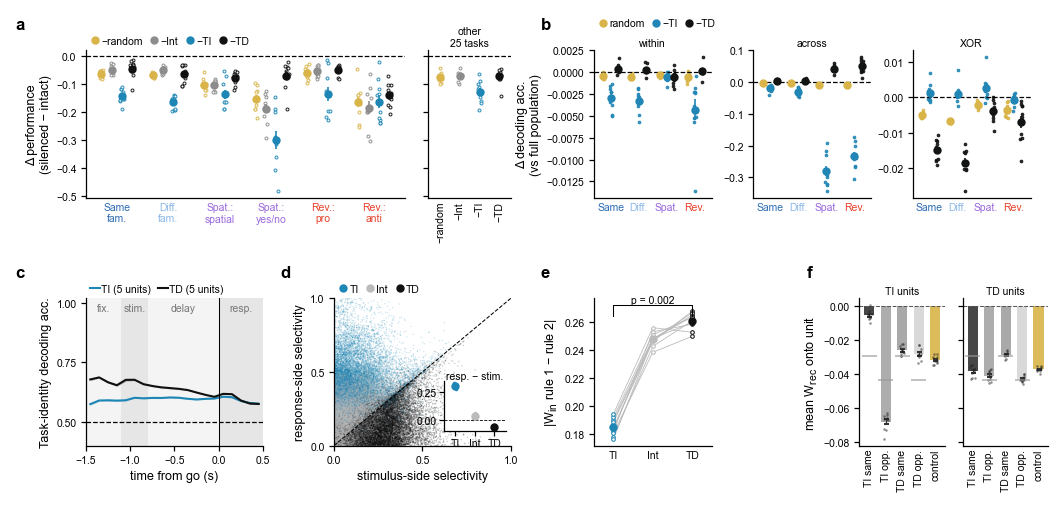

saved analysis/figures/figure_s8/figs8.{pdf,svg,png} and 6 single panels


In [9]:
DRAW = dict(a=draw_a, b=draw_b, c=draw_c, d=draw_d, e=draw_e, f=draw_f)

def build_full():
    fig = plt.figure(figsize=(FIG_W * MM, FIG_H * MM)); AX = {}
    for p, rects in LAYOUT.items():
        AX[p] = [add_axes_mm(fig, *r, FIG_W, FIG_H) for r in rects]; DRAW[p](AX[p])
        l, t = rects[0][0], rects[0][1]
        fig.text((l - 5 - 4) / FIG_W if p not in ('a', 'c') else 2 / FIG_W, 1 - (t - 3) / FIG_H, p, fontsize=8, weight='bold', va='bottom', ha='left')
    return fig, AX

def build_panel(p, ml=13, mb=13, mt=7, mr=3):
    rects = LAYOUT[p]; x0 = min(r[0] for r in rects); y0 = min(r[1] for r in rects)
    w = max(r[0] + r[2] for r in rects) - x0; h = max(r[1] + r[3] for r in rects) - y0; fw, fh = w + ml + mr, h + mt + mb
    if p == 'a': fh += 6
    fig = plt.figure(figsize=(fw * MM, fh * MM))
    axs = [add_axes_mm(fig, r[0] - x0 + ml, r[1] - y0 + mt, r[2], r[3], fw, fh) for r in rects]; DRAW[p](axs)
    return fig

fig, AX = build_full()
fig.savefig(OUT + NAME + '.pdf', facecolor='white'); fig.savefig(OUT + NAME + '.svg', facecolor='white')
fig.savefig(OUT + NAME + '.png', dpi=300, facecolor='white')
plt.show()
for p in LAYOUT:
    f1 = build_panel(p); f1.savefig(PANEL_DIR + f'{p}.pdf', facecolor='white'); plt.close(f1)
print('saved', OUT + NAME + '.{pdf,svg,png}', 'and', len(LAYOUT), 'single panels')

In [10]:
# ── checks: text inside the figure, column / row alignment, category counts ──
fig.canvas.draw(); R = fig.canvas.get_renderer(); fb = fig.bbox; bad = []
for t in fig.findobj(mpl.text.Text):
    if not t.get_visible() or not t.get_text().strip(): continue
    e = t.get_window_extent(R)
    if e.x0 < fb.x0 - .5 or e.y0 < fb.y0 - .5 or e.x1 > fb.x1 + .5 or e.y1 > fb.y1 + .5: bad.append((t.get_text()[:30], [round(v) for v in e.extents]))
print('clipping check:', 'all text inside the figure' if not bad else f'{len(bad)} text artists outside: {bad}')

px = fig.get_figwidth() * 25.4; py = fig.get_figheight() * 25.4
pos = {p: [ax.get_position() for ax in axs] for p, axs in AX.items()}
cols = {1: ['a', 'c'], 2: ['d'], 3: ['b', 'e'], 4: ['f']}
first = lambda p: pos[p[:-1]][1] if p.endswith('2') and p[:-1] in pos else pos[p][0]
for c, ps in cols.items():
    lefts = [first(p).x0 * px for p in ps]; print(f'column {c} {ps}: left edges {np.round(lefts, 2)} mm, spread {np.ptp(lefts):.3f} mm', '✓' if np.ptp(lefts) < .05 else '✗')
rows = {1: ['a', 'b'], 2: ['c', 'd', 'e', 'f']}
for r, ps in rows.items():
    tops = [ax.y1 * py for p in ps for ax in pos[p]]; bots = [ax.y0 * py for p in ps for ax in pos[p]]
    ok = np.ptp(tops) < .05 and np.ptp(bots) < .05 if r != 1 else np.ptp(tops) < .05
    print(f'row {r} {ps}: top spread {np.ptp(tops):.3f} mm, bottom spread {np.ptp(bots):.3f} mm', '✓' if ok else '✗')
n_pairs = pd.Series([Q.relation(a, b, 'shared') for a, b in EC.pairs_of(TASK_ORDER)]).value_counts().reindex(TYPES)
print('category counts', n_pairs.to_dict(), 'sum', n_pairs.sum())
STATS.setdefault('checks', []).extend([f'category counts {n_pairs.to_dict()} (sum {n_pairs.sum()})',
                                       'clipping: ' + ('all text inside the figure' if not bad else f'{len(bad)} artists outside')])

clipping check: all text inside the figure
column 1 ['a', 'c']: left edges [14. 14.] mm, spread 0.000 mm ✓
column 2 ['d']: left edges [56.] mm, spread 0.000 mm ✓
column 3 ['b', 'e']: left edges [100. 100.] mm, spread 0.000 mm ✓
column 4 ['f']: left edges [145.] mm, spread 0.000 mm ✓
row 1 ['a', 'b']: top spread 0.000 mm, bottom spread 0.000 mm ✓
row 2 ['c', 'd', 'e', 'f']: top spread 0.000 mm, bottom spread 0.000 mm ✓
category counts {'same operation': 45, 'different operation': 171, 'spatial vs abstract': 72, 'reversed mapping': 63} sum 351


In [11]:
# ── stats file ──
TITLES = dict(a='a · silencing and behaviour', b='b · removal and decoding, by category', c='c · task identity over time', d='d · stimulus vs response coding',
              e='e · rule-input weights', f='f · recurrent connectivity', checks='checks')
lines = ['# Figure S8 — what TI and TD units do in the multitask RNN: statistics', '',
         'Generated by `analysis/figure_s8.ipynb` from `results/panels/`. Unit of analysis = network (n = 10 unless stated);',
         'paired two-sided Wilcoxon signed-rank tests, exact p (smallest possible with n = 10: 0.002); correlations = MixedLM with a random intercept per network.', '']
# results that differ from what was expected (written from the 2026-10-20 run; re-check if the cache is recomputed)
# results that differ from what was expected (written from the v2 run of 2026-10-20; re-check if the cache is recomputed)
STATS['integrity'] = [
    'a: silencing TD units hurts performance no more than silencing Int units or random choice units, in every category and in either task of the changed-response pairs '
    '(anti task: −TD −0.14 vs −Int −0.18; yes/no task: −0.07 vs −0.19), and no more on the other 25 tasks (−0.073 vs −0.071). TD units are not needed for behaviour in these networks. '
    'Silencing TI units hurts most everywhere except the anti task of reversed pairs, where all four sets do equal damage.',
    'b: the XOR cost of removing TD units is carried by the same- and different-family pairs (−0.015 / −0.018, p = 0.002), where XOR is not a stimulus variable; '
    'it is small and not significant in spatial vs abstract (p = 0.064) and small in reversed-mapping pairs (p = 0.027).',
    'c: TD subsets carry more task identity than TI subsets before go (0.65 vs 0.60, p = 0.002) but not after go (p = 0.064), and not in spatial vs abstract pairs.',
    'd: in reversed-mapping pairs TD units are stimulus-side coders. This makes them an imperfect analog of FEF TD units, which reverse although target and movement '
    'direction agree in both tasks.']
TITLES['integrity'] = 'results that differ from expectation'
for p in ['a', 'b', 'c', 'd', 'e', 'f', 'checks', 'integrity']:
    if p in STATS: lines += [f'## {TITLES[p]}', ''] + [f'- {s}' for s in STATS[p]] + ['']
open(OUT + NAME + '_stats.md', 'w').write('\n'.join(lines)); print('wrote', OUT + NAME + '_stats.md')

wrote analysis/figures/figure_s8/figs8_stats.md


In [12]:
# Supplementary Table 1: write tables/ed_fig8.csv
ST.save()

ED Fig. 8: 82 rows -> analysis/tables/ed_fig8.csv
  rows per panel: a 28, b 36, c 1, d 3, e 4, f 10


,Panel,Dataset,Measure,Group / comparison,n,Unit of n,Mean,s.e.m.,Test,Statistic,P,Notebook location
0,a,Same task family,Δ performance (silenced − intact),−random,10,networks,-0.063422,0.003547,None,None,NaN,"figure_s8.ipynb, cell 4 (a · silencing and tas..."
1,a,Same task family,Δ performance (silenced − intact),−Int,10,networks,-0.049446,0.004873,None,None,NaN,"figure_s8.ipynb, cell 4 (a · silencing and tas..."
2,a,Same task family,Δ performance (silenced − intact),−TI,10,networks,-0.142706,0.007775,None,None,NaN,"figure_s8.ipynb, cell 4 (a · silencing and tas..."
3,a,Same task family,Δ performance (silenced − intact),−TD,10,networks,-0.045601,0.009678,None,None,NaN,"figure_s8.ipynb, cell 4 (a · silencing and tas..."
4,a,Different task family,Δ performance (silenced − intact),−random,10,networks,-0.069372,0.002294,None,None,NaN,"figure_s8.ipynb, cell 4 (a · silencing and tas..."
...,...,...,...,...,...,...,...,...,...,...,...,...
77,f,ReLU networks,Mean W_rec onto TD units,TI same,10,networks,-0.038427,0.001005,None,None,NaN,"figure_s8.ipynb, cell 14 (f · recurrent connec..."
78,f,ReLU networks,Mean W_rec onto TD units,TI opp,10,networks,-0.041004,0.000932,None,None,NaN,"figure_s8.ipynb, cell 14 (f · recurrent connec..."
79,f,ReLU networks,Mean W_rec onto TD units,TD same,10,networks,-0.028626,0.000567,None,None,NaN,"figure_s8.ipynb, cell 14 (f · recurrent connec..."
80,f,ReLU networks,Mean W_rec onto TD units,TD opp,10,networks,-0.042827,0.000629,None,None,NaN,"figure_s8.ipynb, cell 14 (f · recurrent connec..."


## Full page

All panels on one 612 × 792 pt page, laid out like the .ai figure page (`layouts/figure_s8.json`); schematics are dashed placeholders. Output: `figures/figure_s8/figure_s8_full.svg`.

In [13]:
from figure_layout import assemble
assemble('figure_s8')

figure_s8: 1 panel SVGs placed -> analysis/figures/figure_s8/figure_s8_full.svg
   a  figs8.svg                                        scale 1.000 fixed canvas


'analysis/figures/figure_s8/figure_s8_full.svg'